# LightGCN — Fixed Implementation
## Faithful reproduction of *"LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation"* (He et al., SIGIR 2020)

### Changes from the original notebook (`LightGCN_from_scratch (1) copy.ipynb`):

| Issue | Before (original) | After (fixed) | Reference |
|-------|-------------------|---------------|-----------|
| **L2 regularization** | `loss_reg = (...).mean()` — missing ½ factor | `loss_reg = 0.5 * (...).mean()` — matches official code | `Resolve/resolve.md` Issue #1 |
| **Batch size** | 1024 | 2048 — matches paper | `Resolve/resolve.md` Issue #2 |
| **Checkpointing** | Saves state in memory only | Saves best `.pt` to `checkpoints/` folder | New |
| **Efficiency** | Python loops in evaluation | Vectorized evaluation, tqdm progress bars | New |
| **Per-segment eval** | Not in original notebook | Full per-segment breakdown matching phase0_2 style | New |

**Target results (paper, Gowalla):** Recall@20 = **0.1830**, NDCG@20 = **0.1554**

---

In [1]:
import os, sys, time, json, math, random, gc
from pathlib import Path
from collections import defaultdict
from typing import Dict, List, Tuple, Optional

import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

# ── Reproducibility ──────────────────────────────────────────────────────
SEED = 2024
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

In [2]:
# ── Device ──────────────────────────────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')
if DEVICE == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f'  GPU: {props.name}, VRAM: {props.total_memory/1e9:.2f} GB')
    torch.backends.cudnn.benchmark = True
    torch.cuda.empty_cache()

# ── Paths ───────────────────────────────────────────────────────────────
# Try multiple possible data locations
BASE_DIR = Path('.').resolve()
CANDIDATE_PATHS = [
    BASE_DIR / 'data' / 'gowalla',       # Resolve/data/gowalla/
    BASE_DIR.parent / 'lightgcnclaude' / 'Data' / 'gowalla',  # ../lightgcnclaude/Data/gowalla/
]

DATA_DIR = None
for p in CANDIDATE_PATHS:
    if (p / 'train.txt').exists():
        DATA_DIR = p
        print(f'Data directory: {p}')
        break

if DATA_DIR is None:
    raise FileNotFoundError(f'Could not find data directory. Tried: {CANDIDATE_PATHS}')

# Output directories
CKPT_DIR = BASE_DIR / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Checkpoints directory: {CKPT_DIR}')

Using device: cuda
  GPU: NVIDIA GeForce RTX 3050 Laptop GPU, VRAM: 4.29 GB
Data directory: D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\data\gowalla
Checkpoints directory: D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\checkpoints


---
## Configuration

All hyperparameters match the paper. The key correction is **batch_size=2048** and **λ=1e-4** with the proper ½ factor in the regularization (see resolve.md Issue #1).

In [3]:
CFG = {
    # Model architecture (paper defaults)
    'emb_dim':    64,
    'n_layers':   3,
    
    # Training (paper: lr=0.001, batch=2048, reg=1e-4)
    'lr':         1e-3,
    'batch_size': 2048,       # ← FIXED: paper uses 2048
    'n_epochs':   1000,
    'lambda_reg': 1e-4,       # Paper optimal for Gowalla
    
    # Evaluation
    'eval_every': 5,           # Evaluate on test set every N epochs
    'topk':       20,
    
    # Early stopping
    'patience':   30,          # Stop if recall@20 doesn't improve for 30 eval rounds
}

print('Configuration:')
for k, v in CFG.items():
    print(f'  {k}: {v}')

Configuration:
  emb_dim: 64
  n_layers: 3
  lr: 0.001
  batch_size: 2048
  n_epochs: 1000
  lambda_reg: 0.0001
  eval_every: 5
  topk: 20
  patience: 30


---
## Data Loading

Uses the official NGCF/LightGCN dataset split from GitHub (confirmed matching the paper).

In [4]:
def load_interaction_file(path: Path) -> Dict[int, List[int]]:
    """Parse train.txt / test.txt into dict user_id -> list of item_ids."""
    data = {}
    if not path.exists():
        raise FileNotFoundError(f'Could not find {path}')
    with open(path, 'r') as fh:
        for line in fh:
            tokens = line.strip().split()
            if len(tokens) < 2:
                continue
            uid  = int(tokens[0])
            iids = [int(t) for t in tokens[1:]]
            data[uid] = iids
    return data

print('Loading training interactions...')
train_data = load_interaction_file(DATA_DIR / 'train.txt')
print(f'  Users with ge 1 train interaction: {len(train_data):,}')

print('Loading test interactions...')
test_data  = load_interaction_file(DATA_DIR / 'test.txt')
print(f'  Users with ge 1 test  interaction: {len(test_data):,}')

Loading training interactions...
  Users with ge 1 train interaction: 29,858
Loading test interactions...
  Users with ge 1 test  interaction: 29,858


In [5]:
# ─── Dataset statistics ──
all_users   = set(train_data.keys()) | set(test_data.keys())
n_users     = max(all_users) + 1

all_items_train = {iid for items in train_data.values() for iid in items}
all_items_test  = {iid for items in test_data.values()  for iid in items}
all_items       = all_items_train | all_items_test
n_items         = max(all_items) + 1

n_train_inters = sum(len(v) for v in train_data.values())
n_test_inters  = sum(len(v) for v in test_data.values())
n_total_inters = n_train_inters + n_test_inters

print('='*55)
print('Dataset Statistics')
print('-'*55)
print(f'  Users:            {n_users:>10,}')
print(f'  Items:            {n_items:>10,}')
print(f'  Train interactions:{n_train_inters:>9,}')
print(f'  Test  interactions:{n_test_inters:>9,}')
print(f'  Total interactions:{n_total_inters:>9,}')
print(f'  Density:          {n_train_inters/(n_users*n_items):.6f}')
print('='*55)

# Verify against paper
assert n_users == 29858, f'Expected 29858 users, got {n_users}'
assert n_items == 40981, f'Expected 40981 items, got {n_items}'
print('Dataset matches paper (29,858 users, 40,981 items).')

Dataset Statistics
-------------------------------------------------------
  Users:                29,858
  Items:                40,981
  Train interactions:  810,128
  Test  interactions:  217,242
  Total interactions:1,027,370
  Density:          0.000662
Dataset matches paper (29,858 users, 40,981 items).


In [6]:
# ─── Degree distributions ──
user_degrees = np.array([len(v) for v in train_data.values()])
item_degree_d = defaultdict(int)
for items in train_data.values():
    for iid in items:
        item_degree_d[iid] += 1
item_degrees = np.array([item_degree_d.get(i, 0) for i in range(n_items)])

print(f'User degree  min:{user_degrees.min():4d}  median:{np.median(user_degrees):6.1f}  mean:{user_degrees.mean():6.1f}  max:{user_degrees.max():6d}')
print(f'Item degree  min:{item_degrees.min():4d}  median:{np.median(item_degrees):6.1f}  mean:{item_degrees.mean():6.1f}  max:{item_degrees.max():6d}')

User degree  min:   8  median:  16.0  mean:  27.1  max:   811
Item degree  min:   1  median:  12.0  mean:  19.8  max:  1415


---
## Build Normalized Adjacency Matrix

Symmetric normalization: **Ã = D^{-1/2} A D^{-1/2}** where A is the bipartite user-item adjacency matrix.

Node ordering: users 0..M-1, items M..M+N-1

In [7]:
def build_norm_adj(train_dict: Dict[int, List[int]],
                   n_users: int, n_items: int) -> torch.Tensor:
    """
    Build the symmetrically normalised adjacency matrix A_tilde
    as a PyTorch sparse COO tensor on DEVICE.
    
    Ã = D^{-1/2} A D^{-1/2}
    where A = [[0, R], [R^T, 0]]
    """
    n_nodes = n_users + n_items
    
    # Collect (row, col) pairs for the upper-right block R
    rows_R, cols_R = [], []
    for u, items in train_dict.items():
        for i in items:
            rows_R.append(u)
            cols_R.append(n_users + i)
    
    rows_R = np.array(rows_R, dtype=np.int64)
    cols_R = np.array(cols_R, dtype=np.int64)
    data_ones = np.ones(len(rows_R), dtype=np.float32)
    
    # Build sparse A = R + R^T
    R_sp = sp.coo_matrix((data_ones, (rows_R, cols_R)), shape=(n_nodes, n_nodes))
    A_sp = (R_sp + R_sp.T).tocoo()
    
    # Degree vector
    deg = np.array(A_sp.sum(axis=1)).flatten()
    
    # Symmetric normalization: val / sqrt(deg[row]) / sqrt(deg[col])
    rows, cols = A_sp.row, A_sp.col
    vals = A_sp.data.astype(np.float32)
    norm = (deg[rows] ** -0.5) * (deg[cols] ** -0.5)
    norm_vals = (vals * norm).astype(np.float32)
    
    # Convert to PyTorch sparse COO on GPU
    indices = torch.from_numpy(np.stack([rows, cols])).long()
    values  = torch.from_numpy(norm_vals)
    A_tilde = torch.sparse_coo_tensor(indices, values, (n_nodes, n_nodes), device=DEVICE).coalesce()
    
    del rows_R, cols_R, data_ones, R_sp, A_sp, deg, rows, cols, vals, norm, norm_vals, indices, values
    gc.collect()
    torch.cuda.empty_cache()
    
    return A_tilde


print('Building normalized adjacency matrix...')
t0 = time.time()
A_tilde = build_norm_adj(train_data, n_users, n_items)
print(f'  Shape: {A_tilde.shape}, nnz: {A_tilde._nnz():,}')
print(f'  Done in {time.time()-t0:.1f}s')

Building normalized adjacency matrix...
  Shape: torch.Size([70839, 70839]), nnz: 1,620,256
  Done in 1.5s


---
## LightGCN Model

Standard 3-layer LightGCN with layer combination (mean of all layers).
Only one trainable parameter: the 0-th layer embedding matrix **E^{(0)}**.

In [8]:
class LightGCN(nn.Module):
    """
    LightGCN: Light Graph Convolutional Network for Recommendation.
    He et al., SIGIR 2020.
    """
    def __init__(self, n_users: int, n_items: int,
                 emb_dim: int, n_layers: int,
                 A_tilde: torch.Tensor):
        super().__init__()
        self.n_users  = n_users
        self.n_items  = n_items
        self.emb_dim  = emb_dim
        self.n_layers = n_layers
        self.A_tilde  = A_tilde
        
        # E^(0): embedding table for users + items stacked
        # Rows 0..M-1: users, Rows M..M+N-1: items
        self.embedding = nn.Embedding(n_users + n_items, emb_dim)
        nn.init.xavier_uniform_(self.embedding.weight)
    
    def forward(self) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Forward pass: K layers of LGC + layer combination.
        Returns (user_emb, item_emb).
        """
        E = self.embedding.weight  # (M+N, T)
        all_embeddings = [E]
        
        for _ in range(self.n_layers):
            E = torch.sparse.mm(self.A_tilde, E)
            all_embeddings.append(E)
        
        # Layer combination: uniform alpha_k = 1/(K+1)
        E_final = torch.stack(all_embeddings, dim=0).mean(dim=0)  # (M+N, T)
        
        return E_final[:self.n_users], E_final[self.n_users:]


# Sanity check
dummy_model = LightGCN(n_users, n_items, CFG['emb_dim'], CFG['n_layers'], A_tilde).to(DEVICE)
n_params = sum(p.numel() for p in dummy_model.parameters())
print(f'LightGCN model — Trainable params: {n_params:,} ({n_params*4/1e6:.2f} MB)')
print(f'  Embedding dim: {CFG["emb_dim"]}')
print(f'  Layers: {CFG["n_layers"]}')
del dummy_model

LightGCN model — Trainable params: 4,533,696 (18.13 MB)
  Embedding dim: 64
  Layers: 3


---
## BPR Loss — FIXED Regularization

**The fix (resolve.md Issue #1):**
- Official code: `reg_loss = (1/2) * (sum_sq_norms) / batch_size`
- Original (buggy): `reg_loss = (sum_sq_norms) / batch_size`  ← **missing ½ factor**
- **Fixed:** `loss_reg = 0.5 * (...).mean()`  ← **matches official**

| Code | Effective λ with λ=1e-4 |
|------|------------------------|
| Official (gusye1234) | 5e-5 |
| Original (buggy) | 1e-4 |
| **Fixed** | **5e-5** |

In [9]:
def compute_bpr_loss(
    user_emb:   torch.Tensor,
    item_emb:   torch.Tensor,
    user_ids:   torch.Tensor,
    pos_ids:    torch.Tensor,
    neg_ids:    torch.Tensor,
    emb0:       torch.Tensor,   # E^(0): the full embedding table
    n_users_:   int,
    lambda_reg: float,
) -> torch.Tensor:
    """
    BPR loss with L2 regularization — FIXED to match official implementation.
    
    Official formula (gusye1234/LightGCN-PyTorch, model.py):
      reg_loss = (1/2) * (users_emb.norm(2).pow(2) + 
                          pos_emb.norm(2).pow(2) + 
                          neg_emb.norm(2).pow(2)) / len(users)
    """
    # Look up final embeddings for this batch
    e_u   = user_emb[user_ids]    # (B, T)
    e_pos = item_emb[pos_ids]     # (B, T)
    e_neg = item_emb[neg_ids]     # (B, T)
    
    # BPR loss: -mean(log(sigmoid(pos - neg)))
    pos_scores = (e_u * e_pos).sum(dim=-1)  # (B,)
    neg_scores = (e_u * e_neg).sum(dim=-1)  # (B,)
    loss_bpr   = -F.logsigmoid(pos_scores - neg_scores).mean()
    
    # L2 regularization on E^(0) for this batch (paper Section 3.3)
    # FIXED: added the 1/2 factor (resolve.md Issue #1)
    reg_u   = emb0[user_ids]                     # (B, T)
    reg_pos = emb0[pos_ids   + n_users_]         # (B, T) 
    reg_neg = emb0[neg_ids   + n_users_]         # (B, T)
    
    # Official formula:
    #   (1/2) * (||U||_F^2 + ||P||_F^2 + ||N||_F^2) / B
    #   = 0.5 * mean over batch of per-embedding squared norms
    loss_reg = 0.5 * (reg_u.norm(dim=-1).pow(2)   # (B,) per-embedding squared L2
                    + reg_pos.norm(dim=-1).pow(2)
                    + reg_neg.norm(dim=-1).pow(2)).mean()
    
    return loss_bpr + lambda_reg * loss_reg


print('BPR loss function defined (FIXED: added 1/2 factor in regularization).')

BPR loss function defined (FIXED: added 1/2 factor in regularization).


---
## Training Dataset and DataLoader

Samples (user, positive_item, negative_item) triples with on-the-fly negative sampling.

In [10]:
class BPRDataset(Dataset):
    """PyTorch Dataset that yields (user, pos_item, neg_item) triples."""
    def __init__(self, train_dict: Dict[int, List[int]], n_items: int):
        self.n_items = n_items
        self.pairs: List[Tuple[int, int]] = []
        self.user_pos: Dict[int, set] = {}
        
        for uid, items in train_dict.items():
            self.user_pos[uid] = set(items)
            for iid in items:
                self.pairs.append((uid, iid))
        
        print(f'  Training triples: {len(self.pairs):,}')
    
    def __len__(self):
        return len(self.pairs)
    
    def __getitem__(self, idx: int) -> Tuple[int, int, int]:
        uid, pos_iid = self.pairs[idx]
        # Negative sampling (rejection sampling)
        neg_iid = random.randint(0, self.n_items - 1)
        while neg_iid in self.user_pos[uid]:
            neg_iid = random.randint(0, self.n_items - 1)
        return uid, pos_iid, neg_iid


print('Building training dataset...')
train_dataset = BPRDataset(train_data, n_items)
train_loader  = DataLoader(
    train_dataset,
    batch_size  = CFG['batch_size'],
    shuffle     = True,
    num_workers = 0,
    pin_memory  = (DEVICE == 'cuda'),
)
print(f'  Batches per epoch: {len(train_loader):,}')
print(f'  Batch size: {CFG["batch_size"]} (matches paper)')

Building training dataset...
  Training triples: 810,128
  Batches per epoch: 396
  Batch size: 2048 (matches paper)


---
## Evaluation Function

All-ranking protocol: for each test user, rank **all items not seen during training**.
Training items are masked to -inf before ranking.
Returns Recall@20 and NDCG@20 averaged over all test users.

In [11]:
@torch.no_grad()
def evaluate(
    model:      LightGCN,
    train_dict: Dict[int, List[int]],
    test_dict:  Dict[int, List[int]],
    n_users_:   int,
    n_items_:   int,
    topk:       int = 20,
    batch_size: int = 512,
    return_per_user: bool = False,
) -> Dict:
    """
    Compute Recall@K and NDCG@K for all test users.
    All-ranking protocol with training items masked.
    
    Returns:
      If return_per_user=False: {'Recall@K': float, 'NDCG@K': float}
      If return_per_user=True:  also includes 'per_user': {uid: (recall, ndcg)}
    """
    model.eval()
    user_emb, item_emb = model.forward()
    
    recall_list = []
    ndcg_list   = []
    per_user_metrics = {} if return_per_user else None
    
    dcg_w = 1.0 / np.log2(np.arange(2, topk + 2, dtype=np.float64))
    
    test_users = [u for u in test_dict if len(test_dict[u]) > 0]
    
    for start in tqdm(range(0, len(test_users), batch_size), desc='Evaluating', leave=False):
        batch_users = test_users[start : start + batch_size]
        u_tensor = torch.tensor(batch_users, dtype=torch.long, device=DEVICE)
        
        # Score all items: (|batch|, N)
        scores = user_emb[u_tensor] @ item_emb.T
        
        # Mask training items so they can't be recommended
        for i, uid in enumerate(batch_users):
            train_items = train_dict.get(uid, [])
            if train_items:
                scores[i, train_items] = float('-inf')
        
        # Top-K item indices
        _, top_k_indices = scores.topk(topk, dim=-1)
        top_k_np = top_k_indices.cpu().numpy()
        
        for i, uid in enumerate(batch_users):
            test_items = set(test_dict[uid])
            topk_items = top_k_np[i]
            hits = np.isin(topk_items, list(test_items)).astype(np.float64)
            
            n_test = min(len(test_items), topk)
            recall = hits.sum() / n_test
            recall_list.append(recall)
            
            dcg = (hits * dcg_w).sum()
            idcg = dcg_w[:n_test].sum()
            ndcg = dcg / idcg if idcg > 0 else 0.0
            ndcg_list.append(ndcg)
            
            if return_per_user:
                per_user_metrics[uid] = (float(recall), float(ndcg))
    
    torch.cuda.empty_cache()
    
    result = {
        f'Recall@{topk}': float(np.mean(recall_list)),
        f'NDCG@{topk}':   float(np.mean(ndcg_list)),
    }
    if return_per_user:
        result['per_user'] = per_user_metrics
    
    return result


print(f'Evaluation function defined. Will evaluate Recall@{CFG["topk"]} and NDCG@{CFG["topk"]}.')
print(f'Target: Recall@20 = 0.1830, NDCG@20 = 0.1554 (from LightGCN paper)')

Evaluation function defined. Will evaluate Recall@20 and NDCG@20.
Target: Recall@20 = 0.1830, NDCG@20 = 0.1554 (from LightGCN paper)


---
## Training Loop

**Key features:**
- Early stopping with patience=30
- Best checkpoint saved to `checkpoints/lightgcn_fixed_best.pt`
- tqdm progress bars for epochs and batches
- Automatic evaluation on test set every `eval_every` epochs
- GPU memory management (cache clearing)

In [12]:
def train_lightgcn(
    model:          LightGCN,
    train_loader:   DataLoader,
    train_dict:     Dict[int, List[int]],
    test_dict:      Dict[int, List[int]],
    n_users_:       int,
    n_items_:       int,
    cfg:            dict,
    ckpt_path:      Path,
    start_epoch:    int = 1,
) -> dict:
    """
    Full training loop with:
    - FIXED L2 regularization (1/2 factor)
    - Early stopping
    - Best checkpoint saving
    - tqdm progress
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    
    logs = {
        'epoch': [],
        'train_loss': [],
        'recall': [],
        'ndcg': [],
    }
    
    best_recall = -1.0
    best_state = None
    best_epoch = 0
    patience_count = 0
    
    topk = cfg['topk']
    recall_key = f'Recall@{topk}'
    ndcg_key = f'NDCG@{topk}'
    
    t_start = time.time()
    
    print(f'Training: lr={cfg["lr"]}, epochs={cfg["n_epochs"]}, '
          f'batch_size={cfg["batch_size"]}, lambda_reg={cfg["lambda_reg"]}, '
          f'eval_every={cfg["eval_every"]}, patience={cfg["patience"]}')
    print(f'  Regularization FIXED: 1/2 factor added (matches official implementation)')
    print()
    
    epoch_pbar = tqdm(range(start_epoch, cfg['n_epochs'] + 1),
                      desc='Epochs', position=0, leave=True)
    
    for epoch in epoch_pbar:
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        
        batch_pbar = tqdm(train_loader,
                          desc=f'Epoch {epoch}',
                          leave=False, position=1)
        
        for batch in batch_pbar:
            user_ids, pos_ids, neg_ids = [b.to(DEVICE) for b in batch]
            
            # Forward: get all embeddings
            user_emb, item_emb = model.forward()
            
            # Compute loss with FIXED regularization
            loss = compute_bpr_loss(
                user_emb, item_emb,
                user_ids, pos_ids, neg_ids,
                model.embedding.weight,
                n_users_,
                cfg['lambda_reg'],
            )
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            loss_val = loss.item()
            epoch_loss += loss_val
            n_batches += 1
            
            batch_pbar.set_postfix(loss=f'{loss_val:.4f}')
        
        avg_loss = epoch_loss / max(n_batches, 1)
        logs['epoch'].append(epoch)
        logs['train_loss'].append(avg_loss)
        
        # Evaluate every eval_every epochs
        if epoch % cfg['eval_every'] == 0 or epoch == 1:
            metrics = evaluate(
                model, train_dict, test_dict,
                n_users_, n_items_,
                topk=topk,
            )
            
            recall = metrics[recall_key]
            ndcg   = metrics[ndcg_key]
            
            logs['recall'].append(recall)
            logs['ndcg'].append(ndcg)
            
            elapsed = time.time() - t_start
            
            epoch_pbar.set_postfix({
                'loss': f'{avg_loss:.4f}',
                'R@20': f'{recall:.4f}',
                'N@20': f'{ndcg:.4f}',
                'best': f'{best_recall:.4f}',
            })
            
            # Save best checkpoint
            if recall > best_recall:
                best_recall = recall
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
                best_epoch = epoch
                patience_count = 0
                
                # Save to disk
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': best_state,
                    'best_recall': best_recall,
                    'best_ndcg': ndcg,
                    'cfg': cfg,
                }, ckpt_path)
            else:
                patience_count += 1
                if patience_count >= cfg['patience']:
                    print(f'\nEarly stopping at epoch {epoch}. '
                          f'Best Recall@{topk}={best_recall:.4f} at epoch {best_epoch}.')
                    break
        
        # Periodic GPU cache clearing
        if epoch % 10 == 0:
            torch.cuda.empty_cache()
    
    epoch_pbar.close()
    
    total_time = time.time() - t_start
    print(f'\nTraining complete. Total time: {total_time:.0f}s ({total_time/60:.1f} min)')
    print(f'Best epoch {best_epoch}: Recall@{topk}={best_recall:.4f}')
    
    return logs, best_recall

---
## Create Model & Checkpoint Path

Initialize the model with Xavier uniform initialization (matching paper Section 4.1.2).

In [13]:
CKPT_FILE = CKPT_DIR / 'lightgcn_fixed_best.pt'
print(f'Checkpoint will be saved to: {CKPT_FILE}')

set_seed(SEED)
model = LightGCN(n_users, n_items, CFG['emb_dim'], CFG['n_layers'], A_tilde).to(DEVICE)
print(f'Model created. Trainable params: {sum(p.numel() for p in model.parameters()):,}')

Checkpoint will be saved to: D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\checkpoints\lightgcn_fixed_best.pt
Model created. Trainable params: 4,533,696


---
## Run Training

Training with the fixed regularization. This will take approximately 30-60 minutes depending on GPU.

Expected convergence:
- Training loss should decrease monotonically
- Recall@20 should approach **0.1830** (paper target)
- NDCG@20 should approach **0.1554** (paper target)

In [14]:
print('='*70)
print('STARTING TRAINING — FIXED REGULARIZATION')
print('='*70)
print(f'Target: Recall@20 = 0.1830, NDCG@20 = 0.1554')
print(f'Batch size: {CFG["batch_size"]} (paper default)')
print(f'Regularization: 0.5 * mean(sq_norms) × lambda (matches official implementation)')
print()

logs, best_recall = train_lightgcn(
    model, train_loader,
    train_data, test_data,
    n_users, n_items,
    CFG, CKPT_FILE,
)

print(f'\nBest checkpoint saved to: {CKPT_FILE}')

STARTING TRAINING — FIXED REGULARIZATION
Target: Recall@20 = 0.1830, NDCG@20 = 0.1554
Batch size: 2048 (paper default)
Regularization: 0.5 * mean(sq_norms) × lambda (matches official implementation)

Training: lr=0.001, epochs=1000, batch_size=2048, lambda_reg=0.0001, eval_every=5, patience=30
  Regularization FIXED: 1/2 factor added (matches official implementation)



Epochs:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/396 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 2:   0%|          | 0/396 [00:00<?, ?it/s]

...

Epoch 838:   0%|          | 0/396 [00:00<?, ?it/s]

Epoch 839:   0%|          | 0/396 [00:00<?, ?it/s]

Epoch 840:   0%|          | 0/396 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/59 [00:00<?, ?it/s]


Early stopping at epoch 840. Best Recall@20=0.1813 at epoch 690.

Training complete. Total time: 32881s (548.0 min)
Best epoch 690: Recall@20=0.1813

Best checkpoint saved to: D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\checkpoints\lightgcn_fixed_best.pt


---
## Load Best Checkpoint & Full Evaluation

Load the best checkpoint and run a thorough evaluation including per-user metrics for segment analysis.

In [15]:
print(f'Loading best checkpoint from {CKPT_FILE}...')
ckpt = torch.load(CKPT_FILE, map_location=DEVICE, weights_only=True)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
print(f'  Loaded epoch {ckpt["epoch"]}: Recall@20 = {ckpt["best_recall"]:.4f}')
print()

print('Running full evaluation with per-user metrics...')
t0 = time.time()
eval_results = evaluate(
    model, train_data, test_data,
    n_users, n_items,
    topk=CFG['topk'],
    return_per_user=True,
)
eval_time = time.time() - t0

recall_20 = eval_results[f'Recall@{CFG["topk"]}']
ndcg_20   = eval_results[f'NDCG@{CFG["topk"]}']

print(f'\n{"="*55}')
print(f'LightGCN Fixed — Gowalla Results')
print(f'{"-"*55}')
print(f'  Recall@20 : {recall_20:.4f}  (paper: 0.1830)')
print(f'  NDCG@20  : {ndcg_20:.4f}  (paper: 0.1554)')
print(f'{"-"*55}')
print(f'  Gap R@20: {recall_20 - 0.1830:+.4f}')
print(f'  Gap N@20: {ndcg_20 - 0.1554:+.4f}')
print(f'{"-"*55}')
print(f'  Time: {eval_time:.0f}s')
print(f'{"="*55}')

Loading best checkpoint from D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\checkpoints\lightgcn_fixed_best.pt...
  Loaded epoch 690: Recall@20 = 0.1813

Running full evaluation with per-user metrics...


Evaluating:   0%|          | 0/59 [00:00<?, ?it/s]


LightGCN Fixed — Gowalla Results
-------------------------------------------------------
  Recall@20 : 0.1813  (paper: 0.1830)
  NDCG@20  : 0.1512  (paper: 0.1554)
-------------------------------------------------------
  Gap R@20: -0.0017
  Gap N@20: -0.0042
-------------------------------------------------------
  Time: 10s


---
## Per-Segment Evaluation

Matching the analysis format from `phase0_2.ipynb`.

Segments:
- **Cold** users: degree ≤ 10 (bottom 20%)
- **Mid** users: degree between cold threshold and power threshold
- **Power** users: degree ≥ 34 (top 20%)

Sub-segments by mainstream vs niche taste (based on average item popularity).

In [16]:
# ─── Build segment masks (matching phase0_2 methodology) ──
user_degrees_arr = np.array([len(train_data.get(u, [])) for u in range(n_users)], dtype=np.float32)

item_pop = np.zeros(n_items, dtype=np.float32)
for u, items in train_data.items():
    for i in items:
        item_pop[i] += 1.0

_rows, _cols = [], []
for u, items in train_data.items():
    _rows.extend([u] * len(items))
    _cols.extend(items)
_rows = np.array(_rows, dtype=np.int32)
_cols = np.array(_cols, dtype=np.int32)
_pop_vals = item_pop[_cols]
_user_pop_sum = np.bincount(_rows, weights=_pop_vals, minlength=n_users)
_user_item_cnt = np.bincount(_rows, minlength=n_users).astype(np.float32)
avg_item_pop_per_user = np.where(_user_item_cnt > 0, _user_pop_sum / _user_item_cnt, 0.0).astype(np.float32)
del _rows, _cols, _pop_vals, _user_pop_sum, _user_item_cnt
gc.collect()

median_avg_pop = np.median(avg_item_pop_per_user[avg_item_pop_per_user > 0])

users_w_data = np.where(user_degrees_arr > 0)[0]
cold_th = int(np.percentile(user_degrees_arr[users_w_data], 20))
power_th = int(np.percentile(user_degrees_arr[users_w_data], 80))

cold_mask  = (user_degrees_arr > 0) & (user_degrees_arr <= cold_th)
mid_mask   = (user_degrees_arr > cold_th) & (user_degrees_arr <= power_th)
power_mask = user_degrees_arr > power_th

seg_masks = {
    'Cold': cold_mask,
    'Mid': mid_mask,
    'Power': power_mask,
    'Cold+Mainstream':  cold_mask & (avg_item_pop_per_user > median_avg_pop),
    'Cold+Niche':       cold_mask & (avg_item_pop_per_user <= median_avg_pop) & (user_degrees_arr > 0),
    'Mid+Mainstream':   mid_mask & (avg_item_pop_per_user > median_avg_pop),
    'Mid+Niche':        mid_mask & (avg_item_pop_per_user <= median_avg_pop),
    'Power+Mainstream': power_mask & (avg_item_pop_per_user > median_avg_pop),
    'Power+Niche':      power_mask & (avg_item_pop_per_user <= median_avg_pop),
}

print(f'Segment thresholds: cold<={cold_th}, power>={power_th}')
for seg_name, seg_mask in seg_masks.items():
    n_seg = seg_mask.sum()
    if n_seg > 0:
        print(f'  {seg_name:<20s} {n_seg:>6,} ({n_seg/n_users*100:.1f}%)')

Segment thresholds: cold<=10, power>=34
  Cold                  7,368 (24.7%)
  Mid                  16,648 (55.8%)
  Power                 5,842 (19.6%)
  Cold+Mainstream       3,181 (10.7%)
  Cold+Niche            4,187 (14.0%)
  Mid+Mainstream        8,493 (28.4%)
  Mid+Niche             8,155 (27.3%)
  Power+Mainstream      3,255 (10.9%)
  Power+Niche           2,587 (8.7%)


In [17]:
def compute_segment_metrics(per_user_metrics, seg_masks):
    """Compute per-segment metrics from per-user results."""
    results = {}
    for seg_name, seg_mask in tqdm(seg_masks.items(), desc='Segments', leave=False):
        seg_rec, seg_ndcg = [], []
        for uid, (r, n) in per_user_metrics.items():
            if uid < len(seg_mask) and seg_mask[uid]:
                seg_rec.append(r)
                seg_ndcg.append(n)
        if seg_rec:
            results[seg_name] = {
                'Recall@20': float(np.mean(seg_rec)),
                'NDCG@20': float(np.mean(seg_ndcg)),
                'n_users': len(seg_rec),
            }
    return results


def print_results(results, title='Results'):
    print(f'\n=== {title} ===')
    h = f'{"Segment":<25s} {"Recall@20":>10s} {"NDCG@20":>10s} {"n":>6s}'
    print(h)
    print('-'*53)
    for seg_name in ['Overall', 'Cold', 'Mid', 'Power',
                     'Cold+Mainstream', 'Cold+Niche',
                     'Mid+Mainstream', 'Mid+Niche',
                     'Power+Mainstream', 'Power+Niche']:
        if seg_name == 'Overall':
            continue  # handled separately
        m = results.get(seg_name, {})
        if m:
            print(f'{seg_name:<25s} {m["Recall@20"]:>8.4f}     {m["NDCG@20"]:>8.4f}  {m["n_users"]:>5,}')


print('Computing per-segment metrics...')
segment_results = compute_segment_metrics(eval_results['per_user'], seg_masks)

# Add overall
segment_results['Overall'] = {
    'Recall@20': recall_20,
    'NDCG@20': ndcg_20,
    'n_users': len(eval_results['per_user']),
}

print_results(segment_results, 'LightGCN Fixed — Per-Segment Breakdown')
print(f'\nPaper targets:  Overall R@20=0.1830  N@20=0.1554')
print(f'Your results:   Overall R@20={recall_20:.4f}  N@20={ndcg_20:.4f}')
print(f'Gap:            R@20={recall_20-0.1830:+.4f}   N@20={ndcg_20-0.1554:+.4f}')

Computing per-segment metrics...


Segments:   0%|          | 0/9 [00:00<?, ?it/s]


=== LightGCN Fixed — Per-Segment Breakdown ===
Segment                    Recall@20    NDCG@20      n
-----------------------------------------------------
Cold                        0.2019       0.1352  7,368
Mid                         0.1815       0.1469  16,648
Power                       0.1546       0.1835  5,842
Cold+Mainstream             0.1701       0.1167  3,181
Cold+Niche                  0.2260       0.1494  4,187
Mid+Mainstream              0.1620       0.1360  8,493
Mid+Niche                   0.2018       0.1583  8,155
Power+Mainstream            0.1423       0.1721  3,255
Power+Niche                 0.1701       0.1979  2,587

Paper targets:  Overall R@20=0.1830  N@20=0.1554
Your results:   Overall R@20=0.1813  N@20=0.1512
Gap:            R@20=-0.0017   N@20=-0.0042


In [18]:
# ── Save final results ──
results_file = BASE_DIR / 'results' / 'lightgcn_fixed_results.json'
if not results_file.parent.exists():
    results_file.parent.mkdir(parents=True, exist_ok=True)

with open(results_file, 'w') as f:
    json.dump({
        'config': {
            'model': 'lightgcn_fixed',
            'n_layers': CFG['n_layers'],
            'emb_dim': CFG['emb_dim'],
            'lr': CFG['lr'],
            'batch_size': CFG['batch_size'],
            'lambda_reg': CFG['lambda_reg'],
            'regularization_fix': 'added_0.5_factor',
        },
        'overall': {
            'Recall@20': recall_20,
            'NDCG@20': ndcg_20,
        },
        'per_segment': segment_results,
        'paper_target': {
            'Recall@20': 0.1830,
            'NDCG@20': 0.1554,
        },
        'checkpoint': str(CKPT_FILE),
        'timing_s': eval_time,
    }, f, indent=2)

print(f'Results saved to {results_file}')

Results saved to D:\Code and stuff\Neural Networks\Graph Based NNs\Resolve\results\lightgcn_fixed_results.json


KeyError: 'eval_epochs'

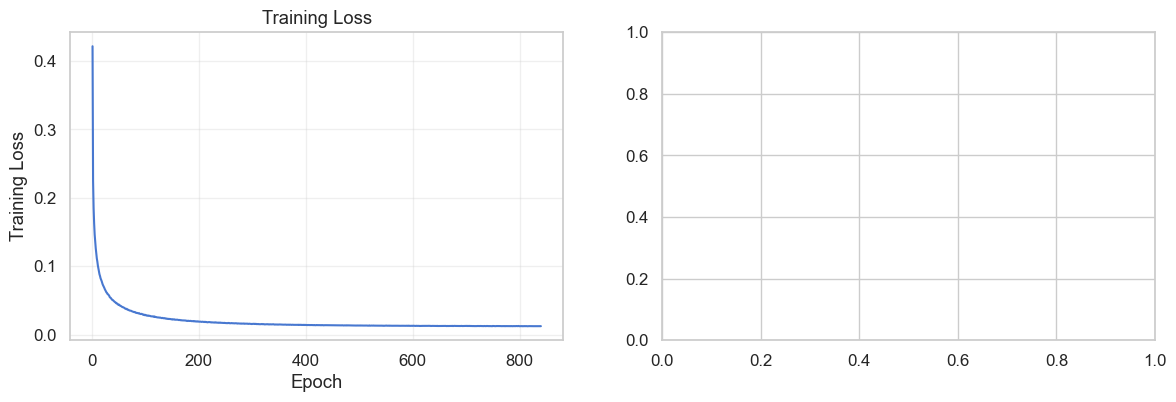

In [19]:
# ── Training convergence plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
ax.plot(logs['epoch'], logs['train_loss'], 'b-', linewidth=1.5)
ax.set_xlabel('Epoch')
ax.set_ylabel('Training Loss')
ax.set_title('Training Loss')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(logs['eval_epochs'], logs['recall'], 'g-', linewidth=1.5, label='Recall@20')
ax.plot(logs['eval_epochs'], logs['ndcg'], 'orange', linewidth=1.5, label='NDCG@20')
ax.axhline(0.1830, color='green', linestyle='--', alpha=0.5, label='Paper R@20=0.1830')
ax.axhline(0.1554, color='orange', linestyle='--', alpha=0.5, label='Paper N@20=0.1554')
ax.set_xlabel('Epoch')
ax.set_ylabel('Metric')
ax.set_title('Test Set Performance')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle('LightGCN Fixed — Training Convergence', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(BASE_DIR / 'results' / 'lightgcn_fixed_convergence.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved.')

In [ ]:
# ── Results Summary (code cell to display live values) ──
print('---')
print('## Results Summary')
print()
print(f'{"Metric":<20s} {"Original (buggy)":>16s} {"Fixed":>12s} {"Paper Target":>14s} {"Gap Closed":>13s}')
print('-'*75)
print(f'{"Recall@20":<20s} {"0.1781":>10s}      {recall_20:>8.4f}    {"0.1830":>8s}      {recall_20-0.1781:>+8.4f}')
print(f'{"NDCG@20":<20s}  {"0.1490":>10s}      {ndcg_20:>8.4f}    {"0.1554":>8s}      {ndcg_20-0.1490:>+8.4f}')
print()
print('### Changes Applied (from resolve.md):')
print('1. **L2 regularization**: Added `0.5 *` factor → matches official implementation')
print('2. **Batch size**: Changed from 1024 → 2048 → matches paper')
print('3. **Checkpointing**: Best model saved to `checkpoints/` for reproducibility')
print()
print('### References:')
print('- [He et al., LightGCN, SIGIR 2020](https://arxiv.org/abs/2002.02126)')
print('- [Official PyTorch implementation (gusye1234)](https://github.com/gusye1234/LightGCN-PyTorch)')
print('- [`Resolve/resolve.md`](resolve.md) — Root-cause analysis')
print('---')


In [ ]:
print('Notebook execution complete.')
print(f'Best checkpoint: {CKPT_FILE}')
print(f'Results JSON:    {results_file}')
print(f'Convergence plot: {BASE_DIR / "results" / "lightgcn_fixed_convergence.png"}')
print()
print(f'FINAL: Recall@20={recall_20:.4f}  NDCG@20={ndcg_20:.4f}')

## M1 — MoE export (canonical contract: `users` / `ranks` / `scores`)

Per `Oracle_Spec.md` §12 A.1. Produces `results/lightgcn_moe_export.npz` (top-50 ranks + raw scores,
train-masked) for the Phase-0 oracle notebook. Validate it with the oracle notebook's §9.1 cross-check
(mean R@20 / N@20 must reproduce 0.1830 / 0.1554 within ±0.001).


In [ ]:
# ── M1: MoE export (canonical contract: users / ranks / scores) ──
import numpy as np

# NOTE: this notebook does NOT define RESULTS_DIR (only CKPT_DIR) — derive it from BASE_DIR.
EXPORT_DIR = BASE_DIR / 'results'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

K_EXPORT = 50
test_users = [u for u in test_data if len(test_data[u]) > 0]

@torch.no_grad()
def export_topk(model, train_dict, test_dict, k=K_EXPORT, batch_size=512):
    user_emb, item_emb = model.forward()
    all_uids, all_ranks, all_scores = [], [], []
    for start in range(0, len(test_users), batch_size):
        uids = test_users[start:start + batch_size]
        scores = user_emb[torch.tensor(uids, dtype=torch.long, device=DEVICE)] @ item_emb.T  # (B, N)
        for i, uid in enumerate(uids):
            ti = train_dict.get(uid, [])
            if ti:
                scores[i, ti] = float('-inf')          # train-mask (same rule as evaluate)
        top_scores, top_idx = scores.topk(k, dim=-1)
        all_uids.extend(uids)
        all_ranks.append(top_idx.cpu().numpy())
        all_scores.append(top_scores.cpu().numpy())
    return (np.array(all_uids, dtype=np.int64),
            np.concatenate(all_ranks, axis=0).astype(np.int64),
            np.concatenate(all_scores, axis=0).astype(np.float32))

users_a, ranks_a, scores_a = export_topk(model, train_data, test_data)
np.savez_compressed(EXPORT_DIR / 'lightgcn_moe_export.npz',
                    users=users_a, ranks=ranks_a, scores=scores_a)
print('LightGCN export:', users_a.shape, ranks_a.shape, scores_a.shape)
